# MongoDB EDA — `banking_support_db`
Collections view, dtypes, null counts, distributions and boxplots (seaborn + matplotlib).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # repo root

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.utils.connection import get_mongo_db

sns.set_theme(style="whitegrid")
db = get_mongo_db()
print("connected:", db.name)

2026-10-16 13:30:55 | INFO     | connections | Creating MongoDB client for mongodb://localhost:27017/banking_support_db


connected: banking_support_db


## 1. Collections view

In [2]:
rows = [{"collection": c, "docs": db[c].estimated_document_count()}
        for c in sorted(db.list_collection_names())]
display(pd.DataFrame(rows))

,collection,docs
0,card_transactions,3000000
1,support_tickets,25000


## 2. Load samples (card_transactions is 3M docs — random $sample)

In [3]:
tickets = pd.DataFrame(list(db["support_tickets"].find({}, {"_id": 0})))
txns = pd.DataFrame(list(db["card_transactions"].aggregate([{"$sample": {"size": 20000}}])))
txns = txns.drop(columns=["_id"], errors="ignore")
for c in ["amount"]:
    txns[c] = pd.to_numeric(txns[c], errors="coerce")
tickets["satisfaction_score"] = pd.to_numeric(tickets["satisfaction_score"], errors="coerce")
for c in ["date_opened", "date_resolved"]:
    tickets[c] = pd.to_datetime(tickets[c], errors="coerce")
print("tickets:", tickets.shape, "| txns sample:", txns.shape)

tickets: (25000, 9) | txns sample: (20000, 8)


In [4]:
def profile(df, name, plot_n=5000):
    """Shape, dtypes, nulls + missing bar and numeric boxplots."""
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(),
                        "null_pct": (df.isna().mean() * 100).round(2)}))
    display(df.head(3))
    display(df.describe(include="all").T)
    miss = (df.isna().mean() * 100).round(2)
    miss = miss[miss > 0].sort_values()
    if len(miss):
        fig, ax = plt.subplots(figsize=(8, max(3, len(miss) * 0.4)))
        miss.plot.barh(ax=ax, color="tomato")
        ax.set_title(f"{name}: missing values (%)")
        ax.set_xlabel("% missing")
        plt.tight_layout(); plt.show()
    else:
        print("no missing values")
    num = df.select_dtypes(include="number").columns.tolist()
    if num:
        p = df[num].sample(n=min(plot_n, len(df)), random_state=42)
        fig, axes = plt.subplots(1, len(num), figsize=(4 * len(num), 4))
        if len(num) == 1:
            axes = [axes]
        for a, c in zip(axes, num):
            sns.boxplot(y=p[c], ax=a)
            a.set_title(c)
        fig.suptitle(f"{name}: numeric boxplots (n={len(p)})")
        plt.tight_layout(); plt.show()
    return df.shape

### support_tickets

--- support_tickets ---
shape: (25000, 9)
                             dtype  nulls  null_pct
ticket_id                      str      0       0.0
customer_id                    str      0       0.0
issue_type                     str      0       0.0
date_opened         datetime64[us]      0       0.0
date_resolved       datetime64[us]      0       0.0
status                         str      0       0.0
satisfaction_score           int64      0       0.0
loaded_at                      str      0       0.0
created_at                     str      0       0.0


,ticket_id,customer_id,issue_type,date_opened,date_resolved,status,satisfaction_score,loaded_at,created_at
0,1,16045,App Login Issue,2024-08-04,2024-08-19,Resolved,5,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:24+00:00
1,2,8088,App Login Issue,2021-07-13,2021-07-27,Resolved,1,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:24+00:00
2,3,47568,Card Blocked,2021-06-23,2021-07-08,Resolved,3,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:24+00:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ticket_id,25000,25000,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,25000,20513,10609,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_type,25000,10,Card Blocked,2560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_opened,25000,NaN,NaN,NaN,2022-09-29 05:57:00.288000,2019-01-01 00:00:00,2020-11-17 00:00:00,2022-10-03 00:00:00,2024-08-06 00:00:00,2026-06-24 00:00:00,NaN
date_resolved,25000,NaN,NaN,NaN,2022-10-08 17:43:21.216000,2019-01-01 00:00:00,2020-11-25 00:00:00,2022-10-12 00:00:00,2024-08-16 00:00:00,2026-07-12 00:00:00,NaN
status,25000,3,Resolved,20051,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaction_score,25000.0,NaN,NaN,NaN,3.00232,1.0,2.0,3.0,4.0,5.0,1.414777
loaded_at,25000,1,2026-10-14T14:11:25.837045+00:00,25000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,25000,1,2026-07-17T08:09:24+00:00,25000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


no missing values


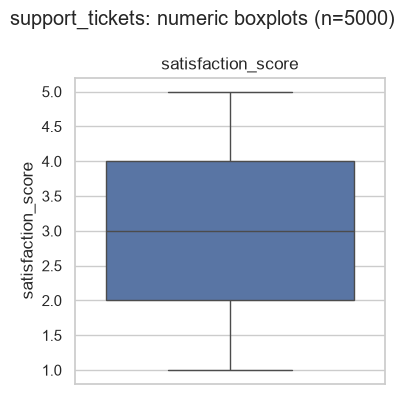

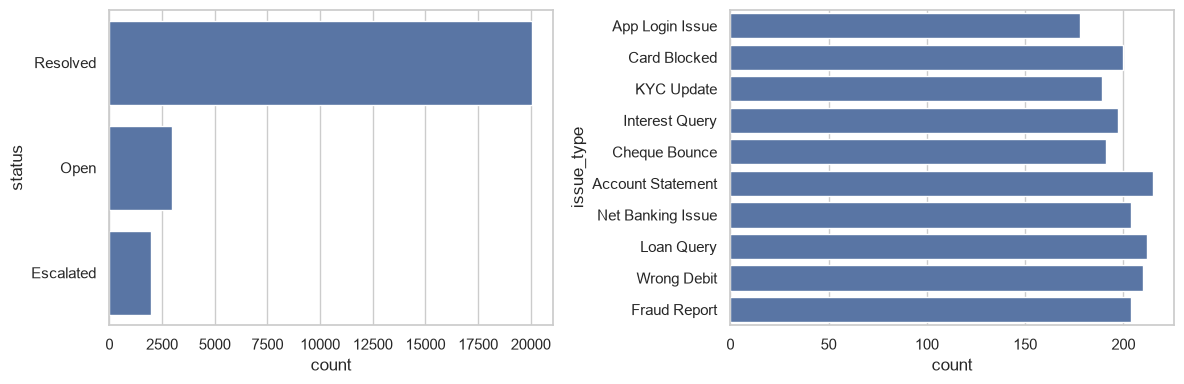

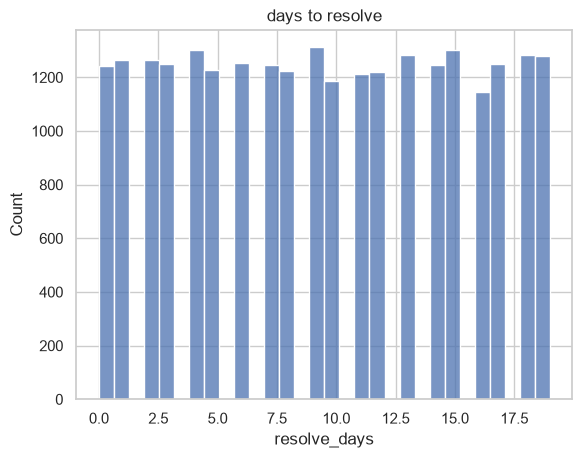

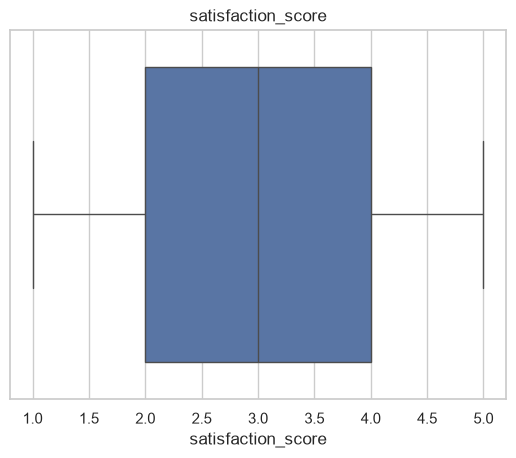

In [5]:
profile(tickets, "support_tickets")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(y=tickets["status"], ax=axes[0])
sns.countplot(y=tickets["issue_type"].head(2000), ax=axes[1])
plt.tight_layout(); plt.show()
tickets["resolve_days"] = (tickets["date_resolved"] - tickets["date_opened"]).dt.days
sns.histplot(tickets["resolve_days"].dropna(), bins=30)
plt.title("days to resolve"); plt.show()
sns.boxplot(x=tickets["satisfaction_score"].dropna())
plt.title("satisfaction_score"); plt.show()

### card_transactions (20k sample)

--- card_transactions ---
shape: (20000, 8)
                     dtype  nulls  null_pct
card_txn_id            str      0       0.0
card_id                str      0       0.0
txn_date               str      0       0.0
merchant_category      str      0       0.0
amount             float64      0       0.0
is_fraud               str      0       0.0
loaded_at              str      0       0.0
created_at             str      0       0.0


,card_txn_id,card_id,txn_date,merchant_category,amount,is_fraud,loaded_at,created_at
0,1122163,37586,2021-09-06,Entertainment,3757.66,0,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:12+00:00
1,888015,24701,2024-09-03,ATM Withdrawal,2956.07,0,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:12+00:00
2,2827715,58,2023-07-25,ATM Withdrawal,1048.32,0,2026-10-14T14:11:25.837045+00:00,2026-07-17T08:09:12+00:00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
card_txn_id,20000,20000,1122163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card_id,20000,17249,17375,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
txn_date,20000,3099,2019-02-10,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,20000,14,Dining,1489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,20000.0,NaN,NaN,NaN,1839.859816,1794.313494,50.01,568.9025,1283.905,2526.4475,16847.72
is_fraud,20000,2,0,19909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,20000,1,2026-10-14T14:11:25.837045+00:00,20000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,20000,1,2026-07-17T08:09:12+00:00,20000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


no missing values


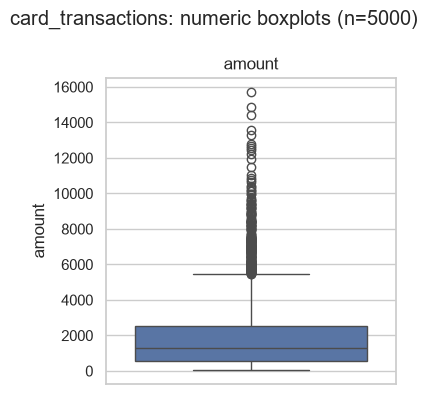

fraud rate: 0.00455


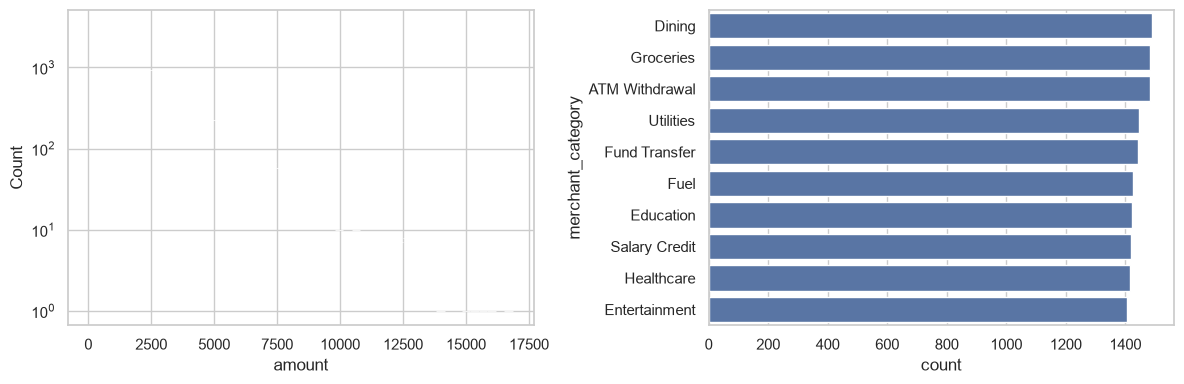

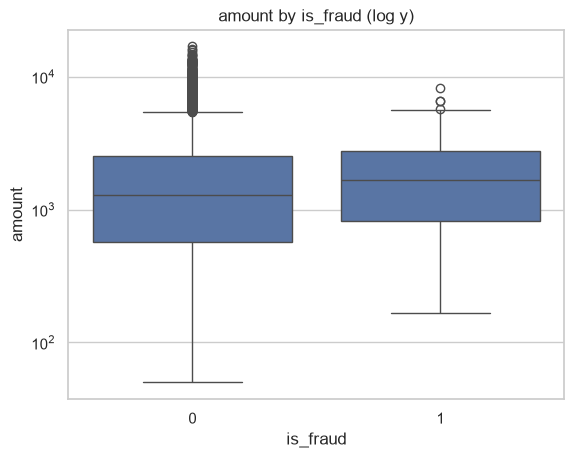

In [6]:
profile(txns, "card_transactions")
print("fraud rate:", (txns["is_fraud"].astype(int) == 1).mean().round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(txns["amount"].dropna(), bins=50, log_scale=(False, True), ax=axes[0])
sns.countplot(y=txns["merchant_category"], order=txns["merchant_category"].value_counts().index[:10], ax=axes[1])
plt.tight_layout(); plt.show()
sns.boxplot(data=txns, x="is_fraud", y="amount")
plt.yscale("log"); plt.title("amount by is_fraud (log y)"); plt.show()